# **THEME 2 : Communication complexe équivalente en bande de base de la 16-QAM**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import special as sp

## **1. Constellation 16-QAM**

**♢ Constellation complexe et code de Gray**

fonction *const16QAM*

In [2]:
def const16QAM() :
    V = np.array([-3, -1, 1, 3])
    I, Q = np.meshgrid(V, V)
    return I + 1j * Q

mComplex = const16QAM()
print(mComplex)

[[-3.-3.j -1.-3.j  1.-3.j  3.-3.j]
 [-3.-1.j -1.-1.j  1.-1.j  3.-1.j]
 [-3.+1.j -1.+1.j  1.+1.j  3.+1.j]
 [-3.+3.j -1.+3.j  1.+3.j  3.+3.j]]


fonction *Gray16QAM*

In [3]:
def Gray16QAM(mComplex) :
    mGray = np.zeros(mComplex.shape[0]**2, dtype=int)
    I = np.real(mComplex)
    I_flat = I.flatten()
    Q = np.imag(mComplex)
    Q_flat = Q.flatten()

    code_gray = {
        -3: "00",
        -1: "01",
         1: "11",
         3: "10"
    }
    for i in range(mGray.size) :
        binaire = code_gray[int(I_flat[i])] + code_gray[int(Q_flat[i])]
        #concatenation des 2 nb binaires
        code = int(binaire, 2) #base 2
        mGray[i] = code
    return mGray.reshape(mComplex.shape)
    

mGray = Gray16QAM(mComplex)
print(mComplex, mGray)

[[-3.-3.j -1.-3.j  1.-3.j  3.-3.j]
 [-3.-1.j -1.-1.j  1.-1.j  3.-1.j]
 [-3.+1.j -1.+1.j  1.+1.j  3.+1.j]
 [-3.+3.j -1.+3.j  1.+3.j  3.+3.j]] [[ 0  4 12  8]
 [ 1  5 13  9]
 [ 3  7 15 11]
 [ 2  6 14 10]]


**♢ Visualisation de la 16-QAM**

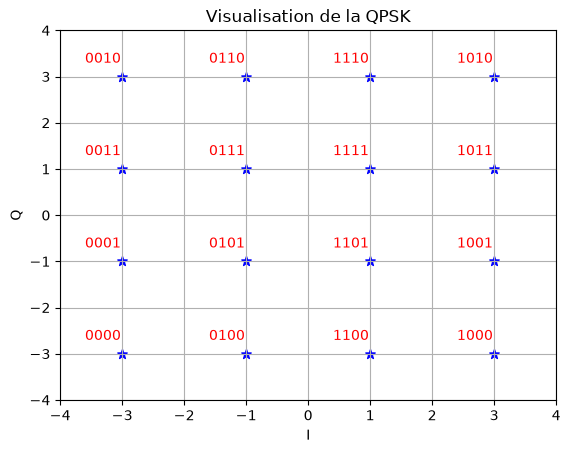

In [4]:
# Paramètre : taille de la constellation (M-QAM)
M = 16
sqrt_M = int(np.sqrt(M))


mComplex = const16QAM()
mGray = Gray16QAM(mComplex)

# Extraire les parties réelle et imaginaire
x = np.real(mComplex).flatten()
y = np.imag(mComplex).flatten()
z = mGray.flatten()

# Créer une nouvelle figure
plt.figure()

# Tracer les points de la constellation
plt.scatter(x, y, s=50, c='blue', marker='*')

# Définir les limites des axes
plt.axis([-sqrt_M, sqrt_M, -sqrt_M, sqrt_M])

# Ajouter les codes de Gray (en binaire) à côté de chaque point
for k in range(M):
    gray_bin = format(z[k], f'0{int(np.log2(M))}b')  # Convertir en binaire avec remplissage
    plt.text(x[k] - 0.6, y[k] + 0.3, gray_bin, color='red')

# Paramètres de la figure
plt.title('Visualisation de la QPSK')
plt.xlabel('I')
plt.ylabel('Q')
plt.grid(True)

# Afficher la figure
plt.show()

**Check point 1:** Bravo! appelez votre encadrant(e) pour valider



---



# **2. Transmission complexe équivalente en bande de base de la 16-QAM**

**♢ Émetteur**

fonction *genBin*

In [5]:
def genBin(N) :
    return np.random.randint(0, 2, size=N)

seq = genBin(512)
print(seq)

[0 1 1 0 0 1 0 1 0 0 1 0 1 1 1 0 1 1 0 0 1 1 0 1 0 1 0 0 1 1 0 1 0 1 0 0 0
 1 1 1 0 0 1 0 1 1 0 1 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 1 1 0 0 1 0 0 1 0
 1 0 0 0 1 1 1 1 1 0 1 1 0 0 1 0 0 1 0 0 1 1 0 0 0 0 1 0 0 1 1 1 1 1 0 0 1
 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 1 1 1 1 1 1 1 1 0 0 1 0 1 0 1 0 0 0 1 1 1 1
 0 1 1 1 0 0 1 1 0 1 1 0 1 1 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 0 1 0 1 1 0 0
 1 1 0 1 0 1 0 0 0 0 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 0 0 0 1 0 0 1 1 0 0 0
 1 1 0 0 1 0 0 0 1 0 0 1 0 1 1 0 0 1 1 1 0 1 1 1 1 1 0 1 0 1 0 0 0 1 0 0 0
 1 0 0 0 1 1 0 0 1 1 0 1 0 0 1 0 1 1 0 1 1 0 0 0 1 0 1 0 1 1 1 0 0 0 0 0 0
 0 0 1 0 0 0 1 0 0 1 1 0 1 0 0 1 1 1 1 1 1 0 0 0 1 0 1 1 1 0 0 1 1 1 0 0 1
 1 1 1 1 1 1 0 0 0 0 0 1 1 1 0 1 1 0 1 1 0 1 0 0 1 1 1 0 0 1 1 0 0 1 1 0 0
 1 1 0 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 0 1 1 0 1 1 0 1 0 1 0 0 0 0 0 0 1
 1 1 0 0 0 0 1 0 1 0 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1 1 0 1 0 0 0
 1 1 1 1 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 0 1 0 0 1 1
 0 1 0 0 0 0 0 1 0 1 0 1 

 fonction *mappingGray*

In [6]:
def mappingGray(seq, mComplex, mGray) :

    S = seq.reshape(seq.size // 4, 4)

    poids = np.array([8, 4, 2, 1]) #valeur de poids des bits
    dec = S.dot(poids) 
    #vecteur des nb decimaux de chaque seq
    
    a_n = np.zeros(dec.size, dtype=complex)
    
    for i in range(dec.size):
        ligne, colonne = np.where(mGray == dec[i])
        a_n[i] = mComplex[ligne[0], colonne[0]]
        #ligne et colonne renvoient la valeur en np.array
        #donc on utilise le [0] pour extraire le int
    return a_n

a_n = mappingGray(seq, mComplex, mGray)

Expliquez pour quoi la séquence des symboles $a_n$ a une taille égale à $N/4$.

N est le nb total de bits, A_n est le nombre de symbole(=paquet de 4 bits).
On a donc N/4 paquets de 4 bits.

**♢ Canal complexe AWGN**

fonction *canalAWGN*

In [7]:
def canalAWGN(a_n, sigma_2):
    N_4 = len(a_n) 
    bI = np.sqrt(sigma_2)*np.random.randn(N_4)
    bQ = np.sqrt(sigma_2)*np.random.randn(N_4)
    return a_n + bI + 1j * bQ

Tester et visualiser les symboles reçus $r_n$ sur la même figure que les symboles de la $16$-QAM.

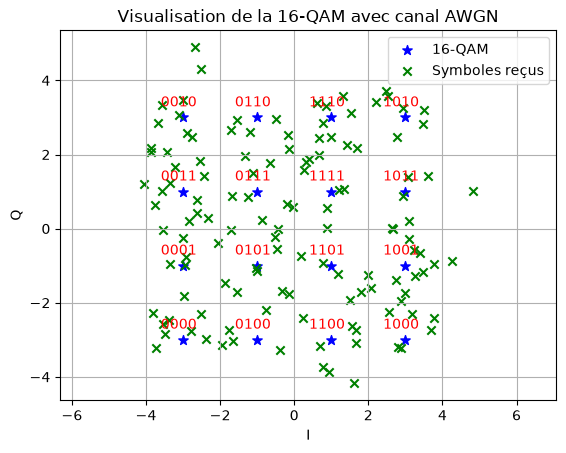

In [8]:
# Extraire les parties réelle et imaginaire
x = np.real(mComplex).flatten()
y = np.imag(mComplex).flatten()
z = mGray.flatten()

# Valeur numérique
N=512
sigma_2=0.5

# Créer une nouvelle figure
plt.figure()

# Tracer les points de la constellation
plt.scatter(x, y, s=50, c='blue', marker='*', label='16-QAM')

# Définir les limites des axes
plt.axis([-sqrt_M, sqrt_M, -sqrt_M, sqrt_M])

# Ajouter les codes de Gray (en binaire) à côté de chaque point
for k in range(M):
    gray_bin = format(z[k], f'0{int(np.log2(M))}b')
    plt.text(x[k] - 0.6, y[k] + 0.3, gray_bin, color='red')

# Affichage exemple canalAWGN
rn = canalAWGN(a_n, sigma_2)

# Tracer les symboles reçus
plt.scatter(np.real(rn), np.imag(rn), 
            color='green', marker='x', label='Symboles reçus')

# Paramètres de la figure
plt.title('Visualisation de la 16-QAM avec canal AWGN')
plt.xlabel('I')
plt.ylabel('Q')
plt.grid(True)
plt.axis('equal')
plt.legend()

# Afficher la figure
plt.show()

**♢ Récepteur**

Ecrire une fonction pour estimer les symboles

In [9]:
def predict(rn, mComplex):

    constellation = mComplex.flatten()
    a_pred = np.zeros(len(rn), dtype=complex)
    
    for i in range(len(rn)):
        #distance euclidienne entre l'observation et les 16 points possibles
        distances = np.abs(rn[i] - constellation)
        #indice du point avec la distance la plus petite
        indice_min = np.argmin(distances)
        a_pred[i] = constellation[indice_min]
        
    return a_pred

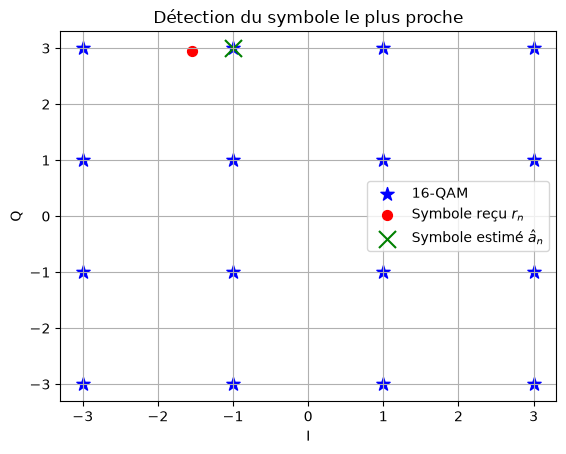

In [10]:
a_pred = predict(rn, mComplex)

# Extraction du premier symbole pour la visualisation
r_test = rn[0]
a_test = a_pred[0]

plt.figure()
plt.scatter(np.real(mComplex), np.imag(mComplex), s=100, c='blue', marker='*', label='16-QAM')
# Afficher le point bruité reçu
plt.scatter(np.real(r_test), np.imag(r_test), s=50, c='red', marker='o', label='Symbole reçu $r_n$')
# Afficher le point estimé choisi par l'algorithme
plt.scatter(np.real(a_test), np.imag(a_test), s=150, c='green', marker='x', label=r'Symbole estimé $\hat{a}_n$')

plt.title("Détection du symbole le plus proche")
plt.xlabel("I")
plt.ylabel("Q")
plt.legend()
plt.grid(True)
plt.show()

 fonction *demapGray*

In [11]:
def demapGray(a_pred, mComplex, mGray):

    poids = np.array([8, 4, 2, 1]) 
    bits = np.zeros(len(a_pred) * 4, dtype=int)

    for i in range(len(a_pred)):
        # position du symbole estimé 
        ligne, colonne = np.where(mComplex == a_pred[i])
        # code de Gray de cette position
        dec = mGray[ligne[0], colonne[0]]
        #divise le decimal par son poids, et le reste de la division euclidienne par 2 donne 0 ou 1
        bits[4*i : 4*i + 4] = (dec // poids) % 2
    return bits

In [12]:
demap_seq = demapGray(a_n, mComplex, mGray)
print("séquence reçue est exactement égale à l'originale ?", np.array_equal(demap_seq, seq))

a_pred = predict(rn, mComplex)
demap_seq = demapGray(a_pred, mComplex, mGray)
#calcul du TEB 
print("TEB = ", np.mean(demap_seq != seq))
#True vaut 1 (bit érroné) et False vaut 0

séquence reçue est exactement égale à l'originale ? True
TEB =  0.048828125


**Check point 2:** Bravo! appelez votre encadrant(e) pour valider



---



**♢ Chaîne de transmission globale**

fonction *chaine16QAM*

In [13]:
def chaine16QAM(N, sigma2, g0):
    
    mComplex = const16QAM()
    mGray = Gray16QAM(mComplex)

    # émetteur
    bits = genBin(N)
    a_n = mappingGray(bits, mComplex, mGray)

    rn = canalAWGN(g0 * a_n, sigma2)

    # récepteur
    a_pred = predict(rn / g0, mComplex)
    d_bits = demapGray(a_pred, mComplex, mGray)

    return bits, d_bits, a_n, a_pred

Tester la fonction

In [14]:
bits, d_bits, a_n, a_pred = chaine16QAM(512, 0.5, 1)

print(len(bits), len(d_bits))     # 512 512
print(len(a_n), len(a_pred))       # 128 128
print("TEB :", np.mean(bits != d_bits))
print("TES :", np.mean(a_n != a_pred))

# sans bruit, tout doit être retrouvé
bits, d_bits, a_n, a_pred = chaine16QAM(512, 0, 1)
print(np.array_equal(bits, d_bits))   # True attendu

512 512
128 128
TEB : 0.06640625
TES : 0.265625
True


# **3. Courbes d’erreur de détection**

**♢ Taux d’erreur binaire et symbole**

Lien entre le RSB et le SNR normalisé:

Calcul de la variance du bruit $\sigma_b^2$ pour chaque valeur $[\frac{E_b}{N_0}]_{dB}$ et le taux d’erreur symbole et binaire correspondants

In [15]:
def sigma2_QAM(EbN0_dB, M, g0=1):
    EbN0 = 10**(EbN0_dB/10)                       # dB -> linéaire
    return (M - 1) * g0**2 / (3 * np.log2(M) * EbN0)

EbN0_dB = np.arange(0, 13)
N = 1000000                                       # multiple de 4

TEB = np.zeros(len(EbN0_dB))
TES = np.zeros(len(EbN0_dB))

for i in range(len(EbN0_dB)):
    sigma2 = sigma2_QAM(EbN0_dB[i], 16)
    bits, d_bits, a_n, a_hat = chaine16QAM(N, sigma2, 1)
    TEB[i] = np.mean(bits != d_bits)
    TES[i] = np.mean(a_n != a_hat)

**♢ Probabilité d’erreur binaire et symbole (théoriques)**

Formule de la probabilité d’erreur binaire $P_{b(\min)}(e)$ :

Tracer la courbe de la probabilité d’erreur binaire pour $M=16$

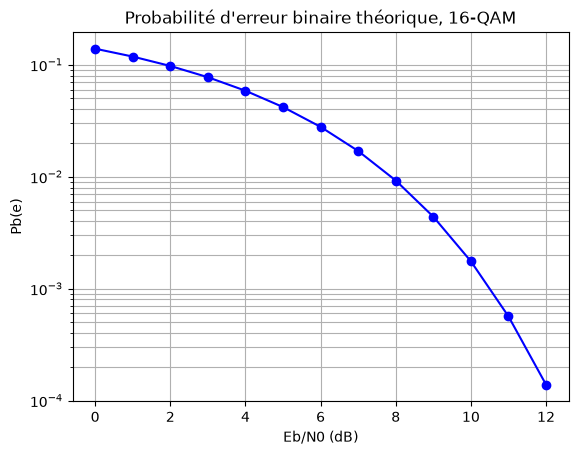

In [16]:
def Q(x):
    return 0.5 * sp.erfc(x / np.sqrt(2))

def Pb_QAM(EbN0_dB, M):
    EbN0 = 10**(np.asarray(EbN0_dB) / 10)
    k = np.log2(M)
    return 4/k * (1 - 1/np.sqrt(M)) * Q(np.sqrt(3*k/(M-1) * EbN0))


Pb_th = Pb_QAM(EbN0_dB, 16)
plt.figure()
plt.semilogy(EbN0_dB, Pb_th, 'b-o')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('Pb(e)')
plt.title('Probabilité d\'erreur binaire théorique, 16-QAM')
plt.grid(True, which='both')
plt.show()

Relation entre la probabilité d’erreur symbole et $P_{b(\min)}(e)$ :

$$P_s(e)\approx\log_2 M\cdot P_{b(\min)}(e)$$

Avec un codage de Gray, deux symboles voisins ne diffèrent que d'un seul bit. Si le bruit est suffisamment faible, une erreur de symbole est presque toujours une erreur vers un symbole voisin, donc elle entraîne une seule erreur binaire parmi les $\log_2 M$ bits du symbole. Pour $M=16$ : $P_s(e)\approx 4\,P_{b(\min)}(e)$.

Tracer la courbe de la probabilité d’erreur symbole

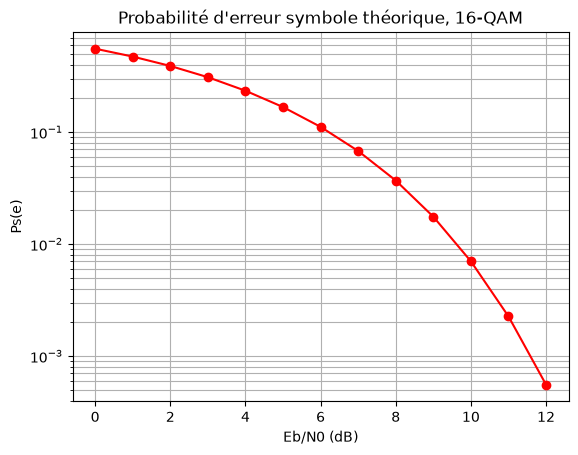

In [17]:
Ps_th = np.log2(16) * Pb_th
plt.figure()
plt.semilogy(EbN0_dB, Ps_th, 'r-o')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('Ps(e)')
plt.title('Probabilité d\'erreur symbole théorique, 16-QAM')
plt.grid(True, which='both')
plt.show()

**♢ Analyse et discussions**

Comparer les courbes estimées avec le simulateur et les courbes théoriques

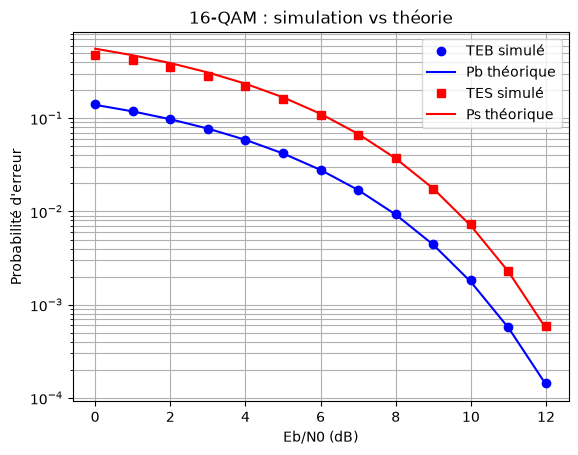

In [18]:
plt.figure()
plt.semilogy(EbN0_dB, TEB, 'bo', label='TEB simulé')
plt.semilogy(EbN0_dB, Pb_th, 'b-', label='Pb théorique')
plt.semilogy(EbN0_dB, TES, 'rs', label='TES simulé')
plt.semilogy(EbN0_dB, Ps_th, 'r-', label='Ps théorique')
plt.xlabel('Eb/N0 (dB)')
plt.ylabel('Probabilité d\'erreur')
plt.title('16-QAM : simulation vs théorie')
plt.legend()
plt.grid(True, which='both')
plt.show()

Commenter : 

**Comparaison simulation / théorie avec $N = 10^6$ bits par point :**



- **Taux d'erreur binaire** : la simulation suit la courbe théorique. Les petits écarts viennent du faible nombre d'erreurs comptées.

- **Taux d'erreur symbole** : il est environ $4$ fois plus élevé que le taux d'erreur binaire à fort rapport signal à bruit, ce qui confirme la relation $P_s(e)\approx\log_2 M\cdot P_{b(\min)}(e)$.

- **Allure des courbes** : les probabilités d'erreur décroissent de plus en plus vite quand $E_b/N_0$ augmente, car elles suivent une fonction $Q(\sqrt{})$ (appelée décroissance quasi gaussienne).

Comparer la communication en bande de base de la BPSK et la communication en bande transposée :

**Comparaison BPSK vs 16-QAM**

(BPSK à gauche des 3 tirets et 16-QAM à droite des 3 tirets)

Bits par symbole :

$1$ --- $\log_2 16 = 4$ 

Débit binaire pour un même $T_s$ :

$R_b = 1/T_s$ --- $R_b = 4/T_s$ 

$E_b/N_0$ requis pour $P_b = 10^{-3}$ :

$\approx 6.8$ dB --- $\approx 10.5$ dB 

Bande occupée (filtre de Nyquist idéal) :

$B = 1/(2T_s)$ --- $B = 1/T_s$ 

Efficacité spectrale $R_b/B$ :

$2$ bit/s/Hz --- $4$ bit/s/Hz

* **Débit binaire** : La 16-QAM transmet 4 fois plus de bits par symbole que la BPSK.
* **Taux d'erreur ($P_b$)** : La 16-QAM fait plus d'erreurs à énergie égale. Ses points étant plus rapprochés, elle exige $\sim 3.7$ dB de plus pour atteindre $P_b = 10^{-3}$.
* **Efficacité spectrale** : Elle est doublée ($4$ contre $2$ bit/s/Hz), ce qui compense la bande plus large due à la transposition en fréquence.
* **Bilan** : La 16-QAM optimise la bande passante, mais nécessite plus de puissance d'émission.

In [19]:
x = np.linspace(0, 15, 1501)
print("pour Pb = ", 10E-3, " on a Eb/N0 = ", x[np.argmin(abs(Pb_QAM(x, 16) - 1e-3))], "dB")

pour Pb =  0.01  on a Eb/N0 =  10.52 dB


***Si le temps imparti permet***, tracer aussi les courbes d’erreur de la QPSK

In [20]:
# code ici

***Si le temps imparti permet***, faire une comparaison complète: BPSK vs. QPSK vs. 16-QAM.

**Check point 3:** Bravo! appelez votre encadrant(e) pour valider